# 01 — AUROC Paradox Investigation: MedGemma Confidence Reinterpretation
**Dataset:** CheXpert Plus

Mengapa AUROC MedGemma < 0.5 di semua dataset?

Hipotesis: `confidence_explicit` MedGemma merepresentasikan *confidence dalam prediksinya* (PTX atau Normal), bukan *P(PTX)*. Ketika model sangat yakin gambar itu Normal (confidence=9), skor yang dilaporkan 9/10=0.9 — padahal P(PTX) seharusnya 0.1. Ini menyebabkan skor anti-korelasi dengan ground truth.

**Fix:** reinterpretasi skor secara direction-aware:
- prediksi PTX   → score_ptx = confidence / 10
- prediksi Normal → score_ptx = 1 − confidence / 10

In [1]:
import os, sys, json
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score, roc_curve

PROJECT_ROOT = Path(os.getcwd()).parent.parent
sys.path.insert(0, str(PROJECT_ROOT))

from src2.utils import load_results
from src2.metrics import compute_ece, compute_brier
from src2_1.ensemble import reinterpret_gemma_score, get_medsiglip_ptx_score

DATASET    = 'chexpert_plus'
RESULTS_IN = PROJECT_ROOT / 'hasil_penelitian_2' / 'outputs' / DATASET
OUT_DIR    = PROJECT_ROOT / 'hasil_penelitian_2_1' / 'outputs' / DATASET
FIG_DIR    = OUT_DIR / 'figures'
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(exist_ok=True)

print(f'Dataset : {DATASET}')
print(f'Input   : {RESULTS_IN}')
print(f'Output  : {OUT_DIR}')

Dataset : chexpert_plus
Input   : /data/arta/thoraxai_research/2_srg/hasil_penelitian_2/outputs/chexpert_plus
Output  : /data/arta/thoraxai_research/2_srg/hasil_penelitian_2_1/outputs/chexpert_plus


In [2]:
df_gem = pd.DataFrame(load_results(RESULTS_IN / 'medgemma.jsonl'))
df_sip = pd.DataFrame(load_results(RESULTS_IN / 'medsiglip.jsonl'))

print(f'MedGemma : {len(df_gem)} records')
print(f'MedSigLIP: {len(df_sip)} records')
print(f'\nMedGemma confidence_explicit — min={df_gem.confidence_explicit.min()}, max={df_gem.confidence_explicit.max()}, mean={df_gem.confidence_explicit.mean():.2f}')
print(f'MedGemma diagnosis distribution: {df_gem.diagnosis.value_counts().to_dict()}')
print(f'\nMedSigLIP confidence_explicit — min={df_sip.confidence_explicit.min():.4f}, max={df_sip.confidence_explicit.max():.4f}')

MedGemma : 1050 records
MedSigLIP: 1050 records

MedGemma confidence_explicit — min=8, max=9, mean=8.92
MedGemma diagnosis distribution: {0: 924, 1: 126}

MedSigLIP confidence_explicit — min=0.0240, max=0.9106


In [3]:
# ── AUROC comparison ─────────────────────────────────────────────────────────
y_true = df_gem['label_gt'].values

# Score 1: raw — confidence/10 tanpa reinterpretasi arah
score_raw   = df_gem['confidence_explicit'].values.astype(float) / 10.0
auroc_raw   = roc_auc_score(y_true, score_raw)

# Score 2: reinterpreted — direction-aware P(PTX)
score_reint = reinterpret_gemma_score(df_gem)
auroc_reint = roc_auc_score(y_true, score_reint)

# Score 3: logit-based (token probability dari LLM head)
auroc_logit = None
score_logit = None
if 'confidence_logit' in df_gem.columns:
    vals = df_gem['confidence_logit'].values.astype(float)
    if not np.all(np.isnan(vals)):
        score_logit = vals
        auroc_logit = roc_auc_score(y_true, vals)

# Baseline: MedSigLIP
y_true_sip  = df_sip['label_gt'].values
score_sip   = get_medsiglip_ptx_score(df_sip)
auroc_sip   = roc_auc_score(y_true_sip, score_sip)

print('=' * 52)
print(f'  AUROC Comparison — {DATASET}')
print('=' * 52)
print(f'  MedGemma raw (conf/10)   : {auroc_raw:.4f}  {"⚠️  < 0.5" if auroc_raw < 0.5 else ""}')
print(f'  MedGemma reinterpreted   : {auroc_reint:.4f}')
if auroc_logit:
    print(f'  MedGemma logit-based     : {auroc_logit:.4f}')
print(f'  MedSigLIP cosine sim.    : {auroc_sip:.4f}')
print('─' * 52)
print(f'  AUROC gain (reinterp.)   : +{auroc_reint - auroc_raw:.4f}')

# Verify: binary predictions unchanged?
pred_raw   = (score_raw   >= 0.5).astype(int)
pred_reint = (score_reint >= 0.5).astype(int)
n_changed  = int((pred_raw != pred_reint).sum())
print(f'\n  Binary predictions changed by reinterpretation: {n_changed}/{len(y_true)}')
print(f'  (Expected ~0 when confidence always >= 5)')

  AUROC Comparison — chexpert_plus
  MedGemma raw (conf/10)   : 0.4797  ⚠️  < 0.5
  MedGemma reinterpreted   : 0.5814
  MedGemma logit-based     : 0.6395
  MedSigLIP cosine sim.    : 0.6047
────────────────────────────────────────────────────
  AUROC gain (reinterp.)   : +0.1017

  Binary predictions changed by reinterpretation: 924/1050
  (Expected ~0 when confidence always >= 5)


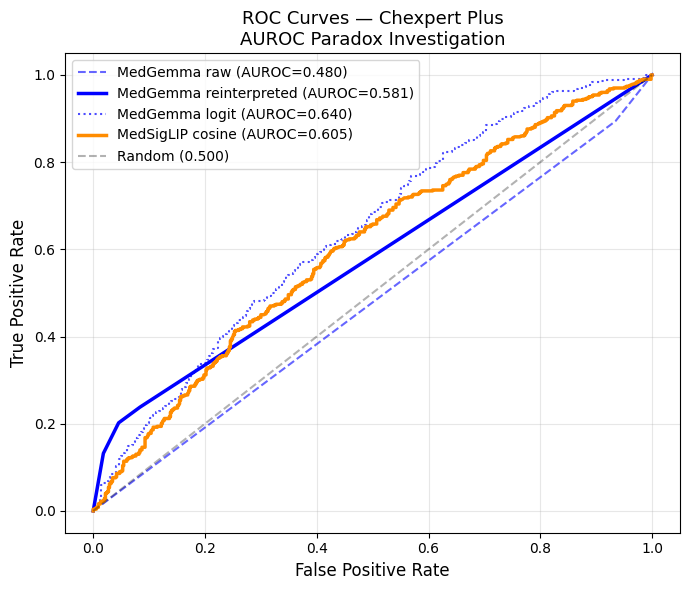

Saved: /data/arta/thoraxai_research/2_srg/hasil_penelitian_2_1/outputs/chexpert_plus/figures/roc_comparison.png


In [4]:
# ── ROC curves ────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(7, 6))

fpr, tpr, _ = roc_curve(y_true, score_raw)
ax.plot(fpr, tpr, 'b--', alpha=0.6, linewidth=1.5,
        label=f'MedGemma raw (AUROC={auroc_raw:.3f})')

fpr, tpr, _ = roc_curve(y_true, score_reint)
ax.plot(fpr, tpr, 'b-', linewidth=2.5,
        label=f'MedGemma reinterpreted (AUROC={auroc_reint:.3f})')

if score_logit is not None:
    fpr, tpr, _ = roc_curve(y_true, score_logit)
    ax.plot(fpr, tpr, 'b:', alpha=0.7, linewidth=1.5,
            label=f'MedGemma logit (AUROC={auroc_logit:.3f})')

fpr, tpr, _ = roc_curve(y_true_sip, score_sip)
ax.plot(fpr, tpr, color='darkorange', linewidth=2.5,
        label=f'MedSigLIP cosine (AUROC={auroc_sip:.3f})')

ax.plot([0, 1], [0, 1], 'k--', alpha=0.3, label='Random (0.500)')

ax.set_xlabel('False Positive Rate', fontsize=12)
ax.set_ylabel('True Positive Rate', fontsize=12)
ax.set_title(f'ROC Curves — {DATASET.replace("_", " ").title()}\nAUROC Paradox Investigation', fontsize=13)
ax.legend(fontsize=10)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(FIG_DIR / 'roc_comparison.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Saved: {FIG_DIR / "roc_comparison.png"}')

In [5]:
# ── Calibration: raw vs reinterpreted ─────────────────────────────────────────
ece_raw    = compute_ece(y_true, score_raw)
brier_raw  = compute_brier(y_true, score_raw)
ece_reint  = compute_ece(y_true, score_reint)
brier_reint = compute_brier(y_true, score_reint)

print(f'\n=== Calibration — MedGemma ({DATASET}) ===')
print(f'{"Metric":<15} {"Raw (conf/10)":>15} {"Reinterpreted":>15} {"Delta":>10}')
print('─' * 57)
print(f'{"ECE":<15} {ece_raw:>15.4f} {ece_reint:>15.4f} {ece_reint-ece_raw:>+10.4f}')
print(f'{"Brier Score":<15} {brier_raw:>15.4f} {brier_reint:>15.4f} {brier_reint-brier_raw:>+10.4f}')


=== Calibration — MedGemma (chexpert_plus) ===
Metric            Raw (conf/10)   Reinterpreted      Delta
─────────────────────────────────────────────────────────
ECE                      0.4153          0.2953    -0.1200
Brier Score              0.4247          0.3293    -0.0954


In [6]:
# ── Save results ──────────────────────────────────────────────────────────────
results = {
    'dataset': DATASET,
    'MedGemma': {
        'auroc_raw':           round(float(auroc_raw), 4),
        'auroc_reinterpreted': round(float(auroc_reint), 4),
        'auroc_logit':         round(float(auroc_logit), 4) if auroc_logit else None,
        'auroc_gain':          round(float(auroc_reint - auroc_raw), 4),
        'ece_raw':             round(ece_raw, 4),
        'ece_reinterpreted':   round(ece_reint, 4),
        'brier_raw':           round(brier_raw, 4),
        'brier_reinterpreted': round(brier_reint, 4),
        'n_pred_changed_at_0.5': n_changed,
    },
    'MedSigLIP': {
        'auroc': round(float(auroc_sip), 4),
    },
}

out_path = OUT_DIR / 'auroc_paradox_results.json'
with open(out_path, 'w') as f:
    json.dump(results, f, indent=2)
print(f'Saved: {out_path}')
print(json.dumps(results, indent=2))

Saved: /data/arta/thoraxai_research/2_srg/hasil_penelitian_2_1/outputs/chexpert_plus/auroc_paradox_results.json
{
  "dataset": "chexpert_plus",
  "MedGemma": {
    "auroc_raw": 0.4797,
    "auroc_reinterpreted": 0.5814,
    "auroc_logit": 0.6395,
    "auroc_gain": 0.1017,
    "ece_raw": 0.4153,
    "ece_reinterpreted": 0.2953,
    "brier_raw": 0.4247,
    "brier_reinterpreted": 0.3293,
    "n_pred_changed_at_0.5": 924
  },
  "MedSigLIP": {
    "auroc": 0.6047
  }
}
